# Convolution as a linear operator

Convolution applies the same local rule at every pixel. A small array of weights, called a **kernel** or **filter**, combines nearby values to produce each output value:

$$y = K * x$$

The star denotes convolution. Once the input size and boundary rule are fixed, this operation is linear and can also be represented by a matrix. We will build that matrix for a one-dimensional blur, then see how sparse matrices and small 2D kernels describe blur, sharpening, edge detection, and the Laplacian.

## 1. A one-dimensional blur is a Toeplitz matrix

Take the three-point averaging kernel `[1/4, 1/2, 1/4]`. At each position, it averages the current value with its two neighbors. We use **zero padding**: values outside the signal are treated as zero.

For a fixed kernel, each output is a weighted sum of input values. Putting those weights into a matrix gives a banded Toeplitz matrix: each diagonal is constant, and only the diagonals near the main diagonal are nonzero.

In [11]:
using LinearAlgebra
using SparseArrays

n = 8
blur_1d = spdiagm(
    -1 => fill(1 / 4, n - 1),
     0 => fill(1 / 2, n),
     1 => fill(1 / 4, n - 1),
)

impulse = zeros(n)
impulse[4] = 1
(Matrix(blur_1d), blur_1d * impulse)

([0.5 0.25 … 0.0 0.0; 0.25 0.5 … 0.0 0.0; … ; 0.0 0.0 … 0.5 0.25; 0.0 0.0 … 0.25 0.5], [0.0, 0.0, 0.25, 0.5, 0.25, 0.0, 0.0, 0.0])

Every row of the matrix applies the same local weights, shifted to the corresponding location. Near the edges, the missing neighbor terms are simply absent, which is exactly the zero-padding rule. The matrix is sparse: it stores only a few nonzero values per row instead of all `n²` entries.

## 2. Verify convolution equals matrix multiplication

Here is the same one-dimensional blur written as a direct local sum. The index expression reverses the kernel around its center, as required by mathematical convolution. This blur kernel is symmetric, so the reversal does not change its values; for an asymmetric kernel, convolution and cross-correlation would differ.

In [12]:
function convolve1d(signal, kernel)
    output = zeros(Float64, length(signal))
    center = (length(kernel) + 1) ÷ 2

    for i in eachindex(signal), k in eachindex(kernel)
        source = i + center - k
        if source in eachindex(signal)
            output[i] += kernel[k] * signal[source]
        end
    end

    output
end

kernel_1d = [1 / 4, 1 / 2, 1 / 4]
signal = [0.0, 0.0, 1.0, 0.5, 0.0, 0.0, 0.8, 0.0]
direct_result = convolve1d(signal, kernel_1d)
matrix_result = blur_1d * signal
(direct_result, matrix_result, norm(direct_result - matrix_result))

([0.0, 0.25, 0.625, 0.5, 0.125, 0.2, 0.4, 0.2], [0.0, 0.25, 0.625, 0.5, 0.125, 0.2, 0.4, 0.2], 0.0)

The last value should be zero up to floating-point rounding. This is the key idea: for fixed input dimensions, convolution is an ordinary linear transformation, and its matrix has structure we can exploit.

## 3. Sparse matrices in two dimensions

A 2D blur can be built from two 1D blurs, one along each image axis. For a small image matrix `X`, Julia stores `vec(X)` column by column, so the combined sparse operator is `kron(T_width, T_height)`. The Kronecker product is still sparse: each output pixel only depends on nearby input pixels.

We will check the matrix representation on a tiny image before applying local kernels to a photograph.

In [13]:
toy_image = reshape(Float64.(1:12), 3, 4)
T_height = spdiagm(-1 => fill(1 / 4, 2), 0 => fill(1 / 2, 3), 1 => fill(1 / 4, 2))
T_width = spdiagm(-1 => fill(1 / 4, 3), 0 => fill(1 / 2, 4), 1 => fill(1 / 4, 3))
blur_2d = kron(T_width, T_height)

(Matrix(blur_2d), nnz(blur_2d))

([0.25 0.125 … 0.0 0.0; 0.125 0.25 … 0.0 0.0; … ; 0.0 0.0 … 0.25 0.125; 0.0 0.0 … 0.125 0.25], 70)

In [14]:
function convolve2d(image, kernel)
    height, width = size(image)
    kernel_height, kernel_width = size(kernel)
    center_row = (kernel_height + 1) ÷ 2
    center_col = (kernel_width + 1) ÷ 2
    output = zeros(Float64, height, width)

    for row in 1:height, col in 1:width
        for kr in 1:kernel_height, kc in 1:kernel_width
            source_row = row + center_row - kr
            source_col = col + center_col - kc
            if 1 <= source_row <= height && 1 <= source_col <= width
                output[row, col] += kernel[kr, kc] * image[source_row, source_col]
            end
        end
    end

    output
end

function convolve_rgb(channels, kernel)
    filtered = cat((convolve2d(view(channels, channel, :, :), kernel) for channel in 1:3)...; dims=3)
    permutedims(filtered, (3, 1, 2))
end

gaussian_kernel = [1 2 1; 2 4 2; 1 2 1] / 16
sparse_result = reshape(blur_2d * vec(toy_image), size(toy_image))
kernel_result = convolve2d(toy_image, gaussian_kernel)
(sparse_result, kernel_result, norm(sparse_result - kernel_result))

([1.3125 3.25 5.5 5.25; 2.25 5.0 8.0 7.5; 2.0625 4.25 6.5 6.0], [1.3125 3.25 5.5 5.25; 2.25 5.0 8.0 7.5; 2.0625 4.25 6.5 6.0], 0.0)

The two results agree up to rounding. `blur_2d` acts on the flattened image as a matrix; `convolve2d` applies the same operation as a local stencil without ever building that large matrix. For a real image, the sparse operator would be enormous even though it has very few nonzero entries per row, so matrix-free stencils are often more practical.

## 4. Apply filters to an image

First, display the original color image. We will then filter a reduced-resolution RGB copy so the lesson stays responsive. Each kernel is applied independently to the red, green, and blue channels. Our stencil uses zero padding at the edges, so filtered values near the image boundary can be affected by the assumed zeros.

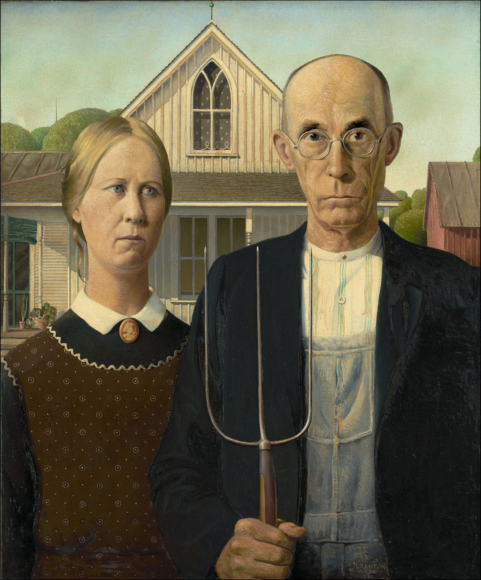

In [15]:
using Images
using ImageIO

image_path = joinpath(@__DIR__, "..", "images", "american-gothic.jpg")
original = load(image_path)
original

In [16]:
color_image = RGB.(original[1:4:end, 1:4:end])
color_channels = Float64.(channelview(color_image))
size(color_image)

(580, 480)

### Blur

A normalized Gaussian-like kernel averages nearby pixels. Its weights sum to one, so regions that are locally constant keep approximately the same brightness.

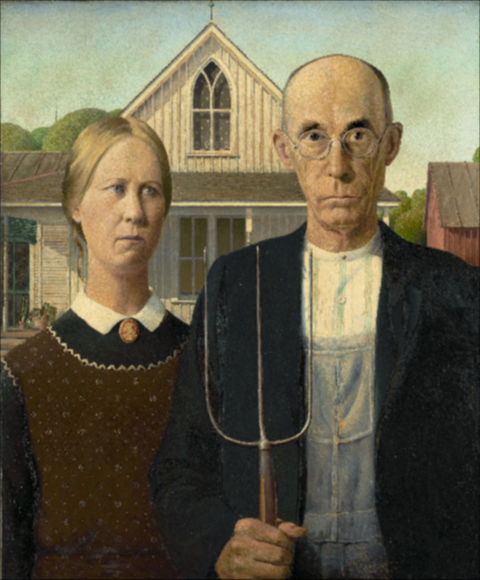

In [17]:
blur_kernel = [1 2 1; 2 4 2; 1 2 1] / 16
blurred = convolve_rgb(color_channels, blur_kernel)
colorview(RGB, clamp.(blurred, 0, 1))

### Sharpen

A sharpening filter adds a scaled center pixel and subtracts its neighbors. This boosts local changes and makes edges appear crisper; clamping is only for displaying the result.

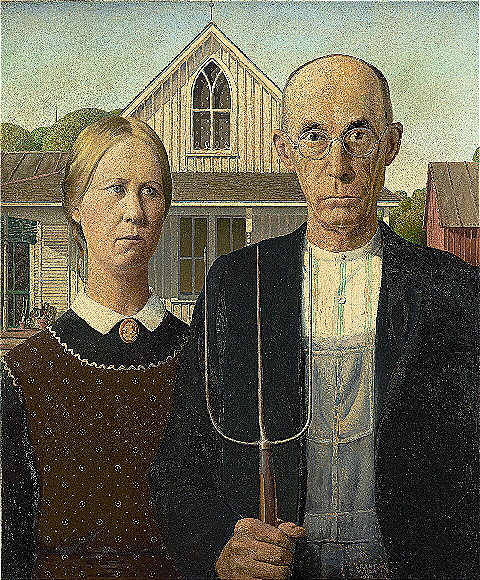

In [18]:
sharpen_kernel = [0 -1 0; -1 5 -1; 0 -1 0]
sharpened = convolve_rgb(color_channels, sharpen_kernel)
colorview(RGB, clamp.(sharpened, 0, 1))

### Edge detection

The Sobel kernels approximate horizontal and vertical derivatives in each color channel. Large responses indicate rapid color changes. We combine the two directions with a gradient magnitude; this removes the sign so both dark-to-light and light-to-dark edges are visible. The edge response is shown in color, with each output channel corresponding to its input channel.

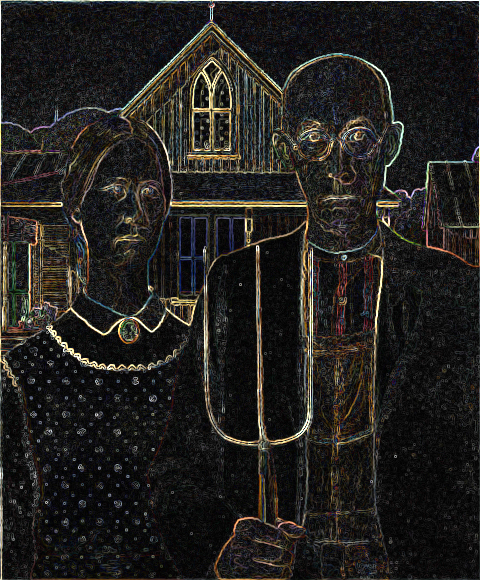

In [19]:
sobel_x = [-1 0 1; -2 0 2; -1 0 1] / 8
sobel_y = sobel_x'
gradient_x = convolve_rgb(color_channels, sobel_x)
gradient_y = convolve_rgb(color_channels, sobel_y)
edge_strength = hypot.(gradient_x, gradient_y)
colorview(RGB, clamp.(4 .* edge_strength, 0, 1))

### Laplacian

The Laplacian combines second differences in the horizontal and vertical directions for each color channel. It responds to changes in the gradient, highlighting fine detail and edges regardless of their direction. Here we display each channel's absolute magnitude; the underlying response is signed.

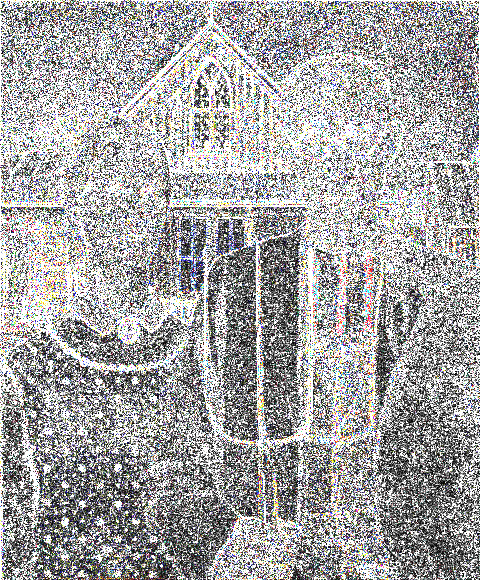

In [20]:
laplacian_kernel = [0 1 0; 1 -4 1; 0 1 0]
laplacian = convolve_rgb(color_channels, laplacian_kernel)
colorview(RGB, clamp.(8 .* abs.(laplacian), 0, 1))

## Your turn

1. Change the blur weights. What does their sum tell you about the brightness of a constant image?
2. Apply the Laplacian to the blurred image. How does removing fine detail affect its response?
3. Add a different center weight to the sharpening kernel. When do values get clipped during display?
4. Change the boundary rule in `convolve2d` from zero padding to clamping indices to the nearest edge. Compare the border artifacts.

The matrix view is useful for understanding linearity and structure. The stencil view is usually the efficient way to apply these operators to large images.